# Modern Makine Öğrenmesi Mimarisi Geliştirme
## Hafta 4 — Boosting Modelleri ve Bagging–Boosting Karşılaştırması

Bu hafta, geçen hafta kurduğum modelleme temelinin üzerine boosting yaklaşımını ekliyorum. Amacım yalnızca hazır bir modeli çalıştırmak değil; her yeni ağacın neden kurulduğunu, önceki modelin hatasını nasıl kullandığını ve modellerin birlikte nasıl karar verdiğini adım adım görmek.

Uygulamada aktüerya öğrencileri için anlaşılır bir problem kullanacağım: **Bir trafik sigortası poliçesinde hasar gerçekleşir mi?** Veri olarak açık kaynaklı French Motor Third-Party Liability veri setini kullanacağım.

### Bu haftanın hedefleri

- Boosting'in temel fikrini anlayabilmek
- Residual, loss ve gradient kavramlarını formüle boğulmadan ilişkilendirmek
- AdaBoost, Gradient Boosting, XGBoost, LightGBM ve CatBoost arasındaki temel farkları görmek
- Bagging ile boosting'i doğru problem bağlamında karşılaştırmak
- Zaman bazlı train/test ayrımıyla gerçekçi bir sigorta modeli kurmak
- Accuracy yerine iş problemine uygun metrikleri tartışmak

## 1. Geçen haftadan bu haftaya

Geçen hafta Decision Tree ve bagging modellerini inceledim. Bagging yaklaşımında birbirinden farklı bootstrap örnekleri oluşturdum, modelleri paralel eğittim ve tahminleri oylama ya da ortalama ile birleştirdim.

Bu hafta farklı bir soru soruyorum:

> Modeller birbirinden bağımsız çalışmak yerine, sırayla çalışıp önceki modelin hatasını düzeltmeye çalışırsa ne olur?

Boosting tam olarak bu fikir üzerine kurulur.

### Boosting'in ana fikri

Boosting'i tek seferde güçlü bir model kurmak yerine, ardışık küçük düzeltmeler yapmak gibi düşünebilirim.

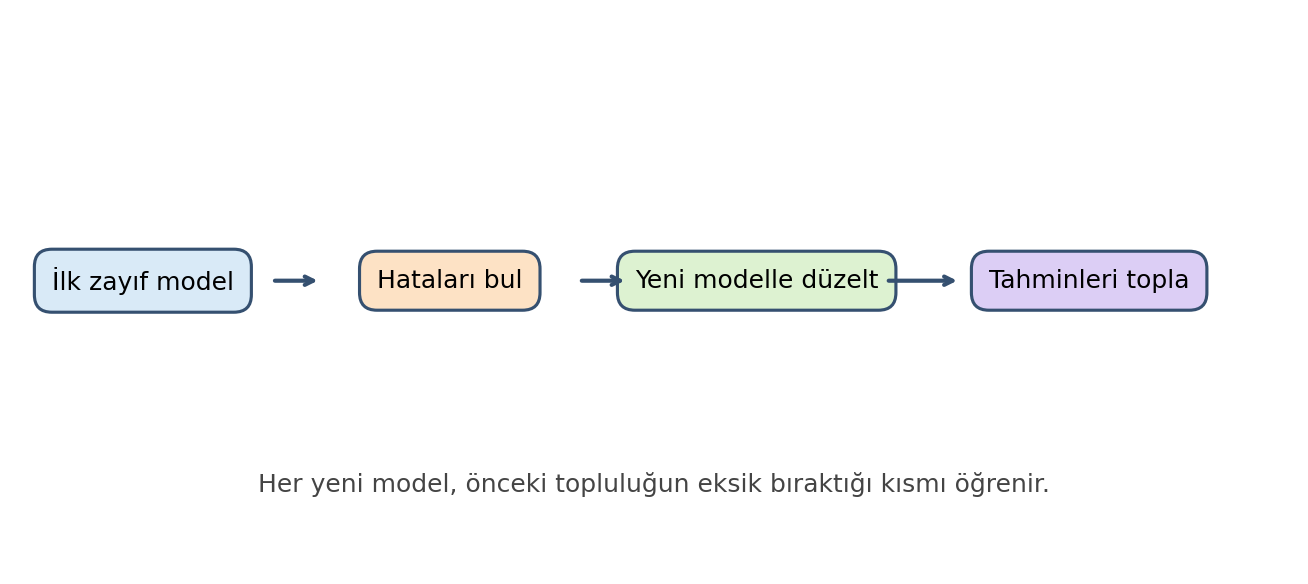

## 2. Boosting nedir?

Boosting, çok sayıda **zayıf öğreniciyi** sıralı şekilde bir araya getirerek güçlü bir tahmin modeli oluşturur. Zayıf öğrenici çoğu zaman az derinlikli küçük bir karar ağacıdır.

Adım adım çalışma biçimi:

1. Önce basit bir tahmin yaparım.
2. Bu tahminlerin nerelerde hata yaptığını ölçerim.
3. Yeni modeli, mevcut hataları azaltacak şekilde eğitirim.
4. Yeni modelin düzeltmesini önceki tahmine eklerim.
5. Aynı işlemi belirlediğim tur sayısı kadar tekrarlarım.

Buradaki kritik fark şudur: Yeni ağaç, sıfırdan bağımsız bir problem çözmez. Önceki topluluğun eksik bıraktığı kısmı öğrenir.

### Zayıf model ne demektir?

Zayıf model, rastgele tahminden biraz daha iyi olan basit modeldir. Örneğin derinliği 1 olan bir karar ağacı yalnızca tek bir soruyla veriyi ikiye böler. Buna **decision stump** denir.

Tek başına böyle bir ağaç karmaşık ilişkiyi öğrenemez. Fakat her yeni ağaç farklı bir hatayı düzelttiğinde, küçük katkıların toplamı güçlü bir modele dönüşebilir.

In [ ]:
# Derinliği 1 olan küçük bir karar ağacı örneği
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

stump = DecisionTreeClassifier(max_depth=1, random_state=42)

# Uygulama bölümünde gerçek veriye fit edeceğim.
print(stump)

## 3. Residual: modelin henüz öğrenemediği kısım

Regresyonda residual'ı basitçe şöyle okuyabilirim:

> Gerçek değer ile mevcut tahmin arasındaki fark.

- Residual pozitifse model düşük tahmin etmiştir.
- Residual negatifse model yüksek tahmin etmiştir.
- Residual sıfıra yaklaştıkça tahmin gerçeğe yaklaşır.

Gradient Boosting'de yeni ağaçlar doğrudan hedefin tamamını tekrar öğrenmek yerine, mevcut modelin residual'larını öğrenmeye çalışır.

### Residual'ları görselleştirelim

Noktalar ile çizgi arasındaki dikey mesafeler, ilk modelin henüz açıklayamadığı kısımları gösterir.

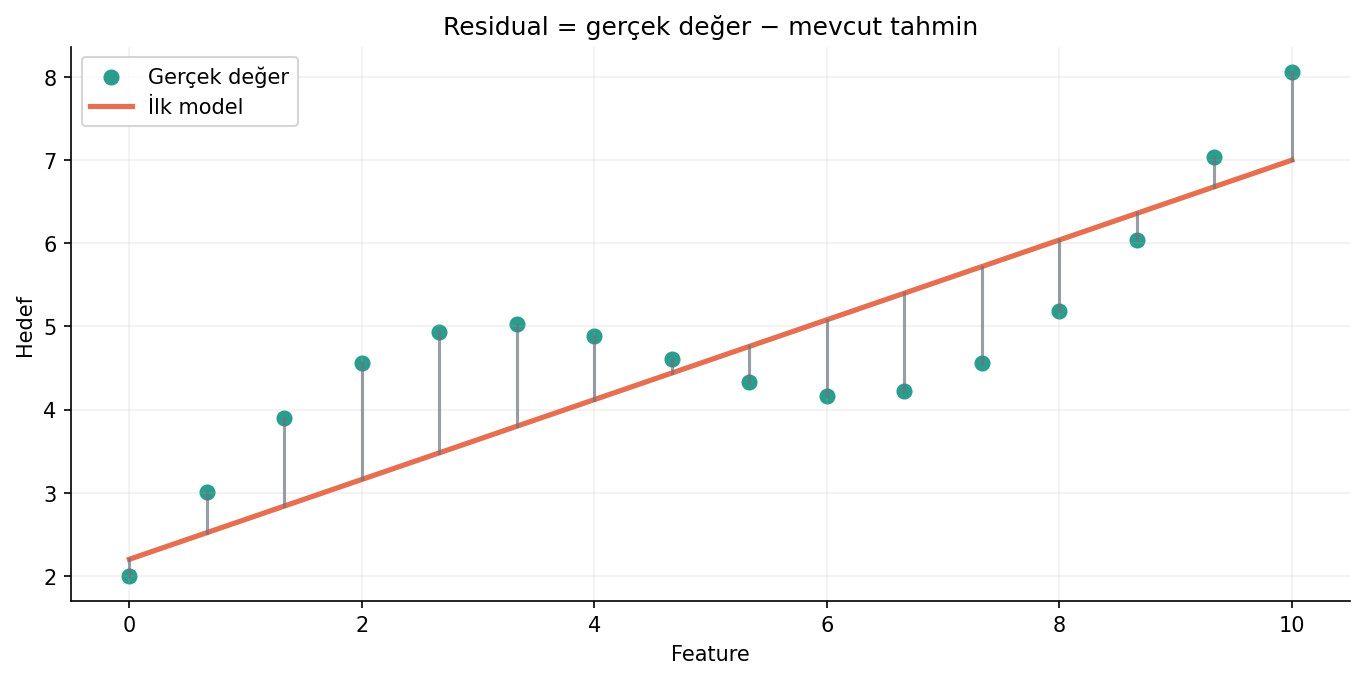

In [ ]:
# Residual mantığını küçük sayılarla görelim.
import pandas as pd

residual_example = pd.DataFrame({
    "gercek_deger": [100, 150, 120, 200],
    "mevcut_tahmin": [90, 170, 115, 160]
})

residual_example["residual"] = (
    residual_example["gercek_deger"]
    - residual_example["mevcut_tahmin"]
)

residual_example

## 4. Gradient Boosting adım adım nasıl çalışır?

Regresyon örneği üzerinden ilerlersem süreç şöyledir:

1. İlk tahmin olarak hedef değişkenin ortalaması gibi basit bir değer kullanırım.
2. Her gözlem için residual hesaplarım.
3. Küçük bir karar ağacını bu residual'ları tahmin edecek şekilde eğitirim.
4. Ağacın ürettiği düzeltmeyi öğrenme oranıyla küçültürüm.
5. Düzeltmeyi mevcut tahmine eklerim.
6. Yeni residual'ları hesaplayıp süreci tekrarlarım.

Modelin son tahmini tek bir ağacın sonucu değildir; başlangıç tahmini ve arkasından gelen küçük düzeltmelerin toplamıdır.

### Küçük düzeltmelerin toplamı

Her turda mevcut tahmine yeni bir düzeltme eklenir. Model giderek daha karmaşık ilişkiyi yakalar.

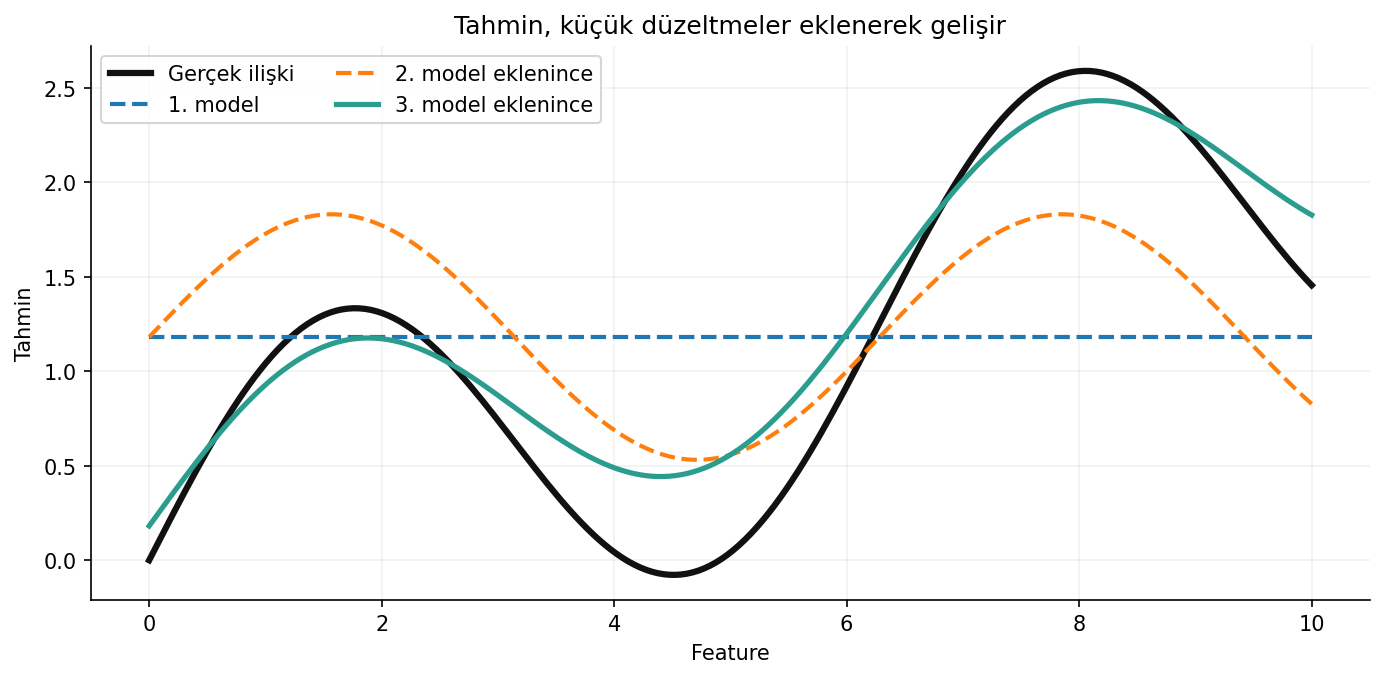

In [ ]:
# Gradient Boosting'in küçük bir regresyon örneğini sklearn kullanmadan canlandırıyorum.
import numpy as np
from sklearn.tree import DecisionTreeRegressor

X_small = np.array([[1], [2], [3], [4], [5], [6]])
y_small = np.array([3, 5, 4, 8, 10, 9], dtype=float)

learning_rate = 0.20
prediction = np.full(len(y_small), y_small.mean())

history = []

for round_no in range(1, 4):
    residual = y_small - prediction

    tree = DecisionTreeRegressor(max_depth=1, random_state=round_no)
    tree.fit(X_small, residual)

    correction = tree.predict(X_small)
    prediction = prediction + learning_rate * correction

    history.append({
        "tur": round_no,
        "ortalama_mutlak_residual": np.abs(y_small - prediction).mean()
    })

pd.DataFrame(history)

## 5. Sınıflandırmada boosting neyi düzeltir?

Sınıflandırmada hedef yalnızca 0 ve 1 olsa da modelin içinde olasılıklarla çalışırım. Modelin yanlış ve aşırı güvenli tahminleri daha büyük loss üretir.

Süreç yine aynıdır:

1. Her sınıf için başlangıç olasılığı oluştururum.
2. Tahmin ile gerçek sınıf arasındaki uyumsuzluğu ölçerim.
3. Yeni ağaç, loss'u azaltacak yönü öğrenir.
4. Ağacın katkısını mevcut skora eklerim.
5. Skoru yeniden olasılığa çeviririm.

Burada gradient kelimesi, loss'u en hızlı azaltacak yönü ifade eder. Her ağacı bu yönde atılan küçük bir adım gibi düşünebilirim.

### Cost function ile bağlantı

Geçen hafta cost function'ın model hatalarını tek bir sayıda topladığını görmüştüm. Boosting'de bu sayı yalnızca sonuç ölçmek için kullanılmaz; bir sonraki modelin hangi yönde ilerlemesi gerektiğini de belirler.

- Regresyonda squared error kullanırsam yeni ağaç residual'lara odaklanır.
- Binary sınıflandırmada log-loss kullanırsam yanlış ve aşırı güvenli tahminlere daha güçlü tepki veririm.
- Farklı loss seçersem modelin “hata” tanımı da değişir.

Bu nedenle loss seçimi yalnızca teknik bir ayar değildir; modelin neyi düzeltmeye çalışacağını belirler.

## 6. AdaBoost nasıl çalışır?

AdaBoost, Gradient Boosting'den farklı bir mekanizma kullanır. Residual üretmek yerine, yanlış sınıflandırılan gözlemlerin ağırlığını artırır.

1. Başlangıçta bütün gözlemlere eşit ağırlık veririm.
2. İlk zayıf modeli eğitirim.
3. Yanlış sınıflandırılan gözlemlerin ağırlığını artırırım.
4. Sonraki model ağırlığı yüksek gözlemlere daha fazla dikkat eder.
5. Başarılı modellere final oylamasında daha yüksek söz hakkı veririm.

Son karar basit çoğunluk oyu değildir; modellerin başarısına göre ağırlıklandırılmış bir oylamadır.

### AdaBoost'un odağı

Büyük daireler, bir önceki modelin yanlış tahmin ettiği ve sonraki turda daha fazla önem kazanacak gözlemleri temsil eder.

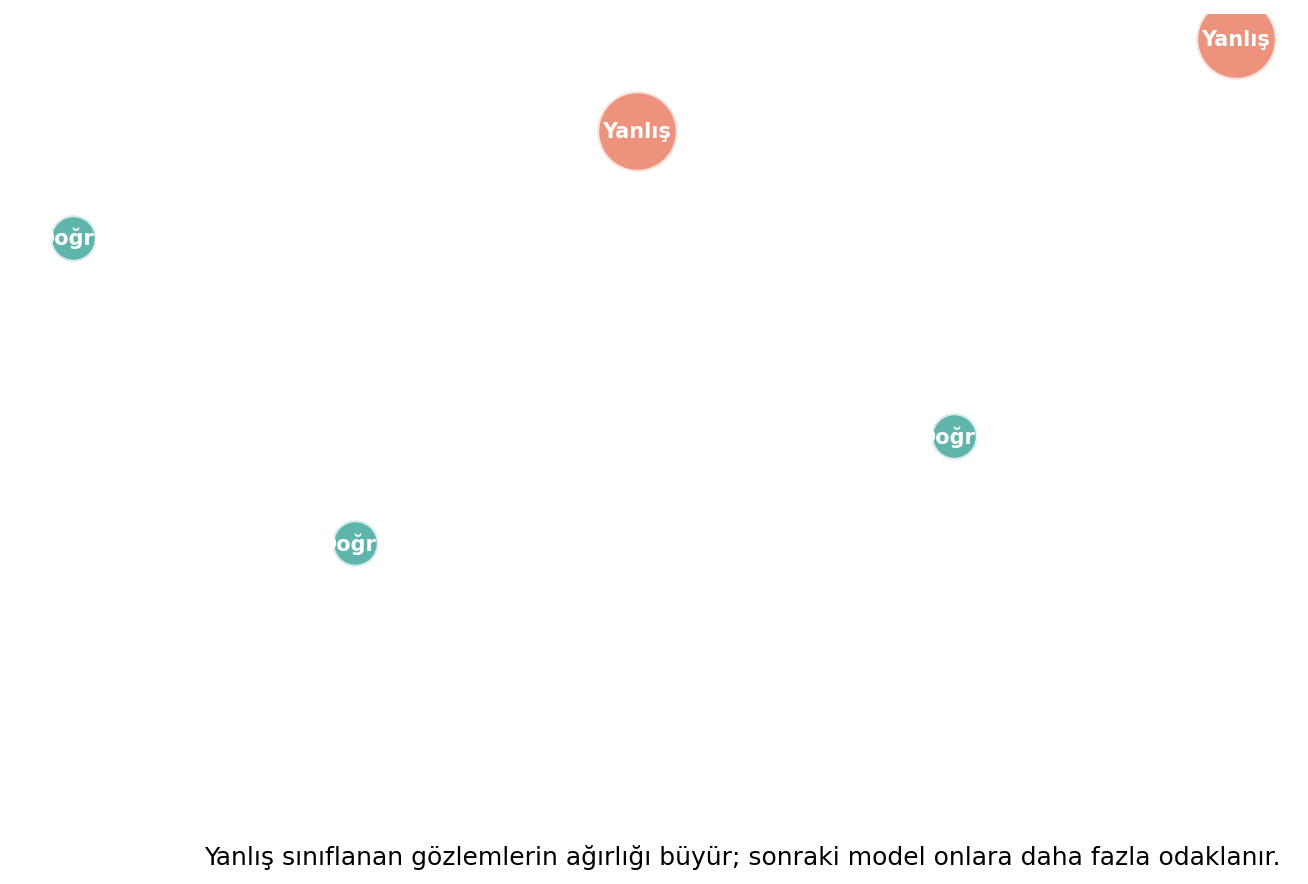

In [ ]:
# AdaBoost ile gözlem ağırlıklarının fikrini küçük bir örnekte gösteriyorum.
weights = np.repeat(1/5, 5)
wrong_predictions = np.array([False, False, True, False, True])

weights[wrong_predictions] *= 2
weights = weights / weights.sum()

pd.DataFrame({
    "yanlis_tahmin": wrong_predictions,
    "yeni_agirlik": weights
})

## 7. Öğrenme oranı neden önemlidir?

Öğrenme oranı, her yeni ağacın final tahmine ne kadar katkı yapacağını belirler.

- Büyük öğrenme oranı hızlı öğrenir; fakat hatalı adımların etkisi de büyük olabilir.
- Küçük öğrenme oranı daha kontrollüdür; fakat daha fazla ağaca ihtiyaç duyar.
- Ağaç sayısını ve öğrenme oranını birbirinden bağımsız düşünmemeliyim.

Genellikle küçük öğrenme oranı + yeterli sayıda ağaç daha dengeli sonuç verir. Ancak gereğinden fazla tur, validation performansını düşürerek overfitting oluşturabilir.

### Learning rate ve early stopping

Training loss azalmaya devam ederken validation loss yeniden yükseliyorsa model artık genellemek yerine eğitim verisini ezberlemeye başlamış olabilir.

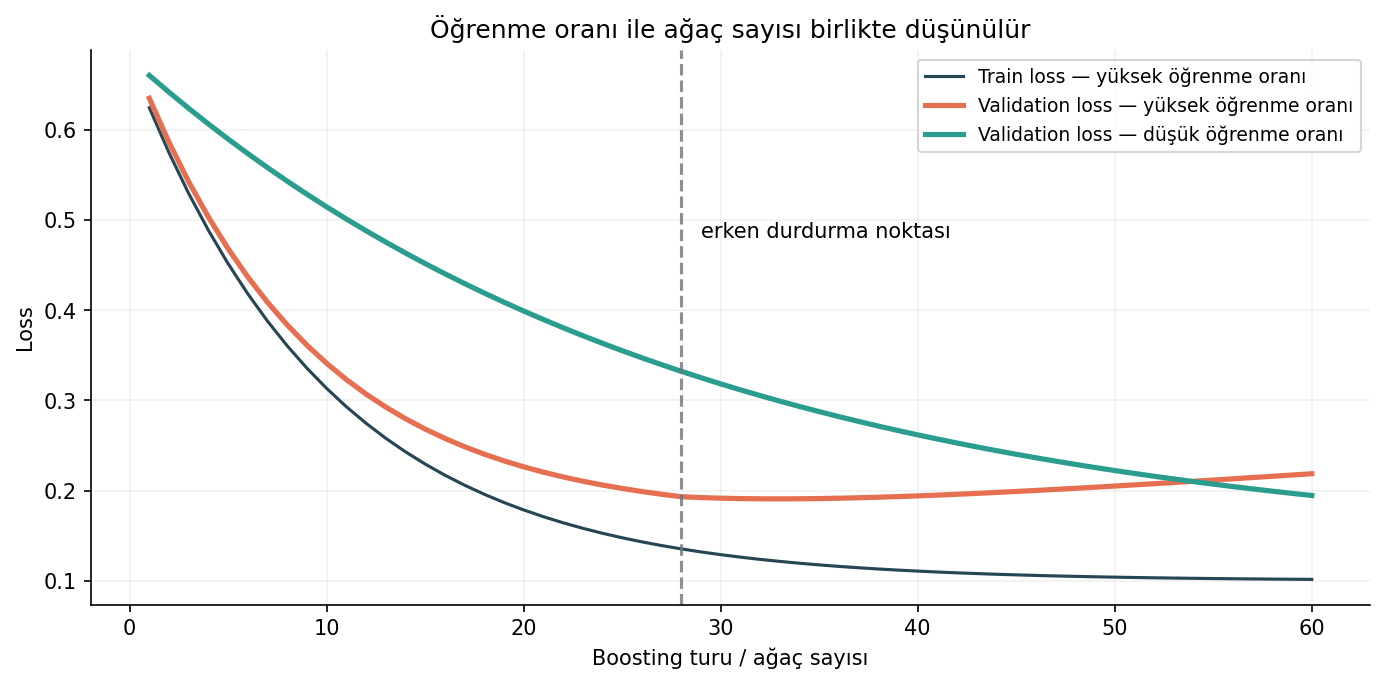

## 8. Boosting ailesindeki modeller

### Gradient Boosting

Klasik ve açıklaması kolay yaklaşımdır. Her ağaç önceki topluluğun hatasını düzeltir. Küçük ve orta büyüklükteki veri setlerinde güçlü bir başlangıç modelidir.

### XGBoost

Gradient Boosting fikrini düzenlileştirme, eksik değer yönetimi, kolon ve satır örnekleme gibi mekanizmalarla güçlendirir. Performansı yüksektir ancak çok sayıda ayarı vardır.

### LightGBM

Büyük tabular verilerde hızlı eğitim için histogram tabanlı bölmeler kullanır. Ağaçları leaf-wise büyütebildiği için hızlı ve güçlüdür; küçük verilerde aşırı öğrenmeye dikkat etmek gerekir.

### CatBoost

Kategorik değişkenleri işlerken hedef bilgisinin sızmasını azaltan özel dönüşümler kullanır. Çok sayıda kategorik değişken içeren problemlerde preprocessing yükünü azaltabilir.

### Aynı ailede olsalar da aynı model değiller

| Model | Güçlü tarafı | Dikkat edeceğim nokta |
|---|---|---|
| AdaBoost | Mantığı sade ve öğretici | Gürültülü gözlemlere duyarlı olabilir |
| Gradient Boosting | Kontrollü ve açıklanabilir başlangıç | Büyük veride yavaşlayabilir |
| XGBoost | Güçlü regularization ve yaygın kullanım | Hiperparametre sayısı fazladır |
| LightGBM | Büyük veride hızlıdır | Leaf-wise büyüme overfitting yapabilir |
| CatBoost | Kategorik feature'larda pratiktir | Eğitim süresi ve model boyutu artabilir |

“En iyi boosting modeli hangisi?” sorusunun tek bir cevabı yoktur. Veri büyüklüğü, kategorik değişkenler, açıklanabilirlik, gecikme ve bakım maliyeti birlikte değerlendirilmelidir.

### 8.1 XGBoost'un arka planı: Daha kontrollü Gradient Boosting

XGBoost, klasik Gradient Boosting fikrini daha kontrollü, düzenlileştirilmiş ve hesaplama açısından verimli hale getirir. Yeni ağacı yalnızca “mevcut hatayı azalt” diyerek kurmaz; kurulacak ağacın gereksiz karmaşıklığını da hesaba katar.

Adım adım düşündüğümde:

1. Mevcut topluluğun her gözlemde ne kadar hata yaptığını hesaplar.
2. Hatanın hangi yönde ve ne kadar hızlı değiştiğine bakar.
3. Aday bölmelerin loss'u ne kadar azaltacağını hesaplar.
4. Yeterli kazanç sağlamayan bölmeleri oluşturmaz veya sonradan budar.
5. Yeni ağacın katkısını öğrenme oranıyla küçültüp topluluğa ekler.

#### XGBoost'u başarılı yapan faktörler

- **Regularization:** Derin ve gereksiz karmaşık ağaçları cezalandırır.
- **İkinci derece bilgi:** Loss'un yalnızca yönünü değil, değişimin yapısını da kullanarak daha bilinçli adımlar atar.
- **Satır ve kolon örnekleme:** Her turda verinin ve feature'ların bir kısmını kullanarak overfitting'i azaltabilir.
- **Eksik değer yönü:** Eksik değerlerin hangi dala gitmesinin daha iyi olduğunu eğitim sırasında öğrenebilir.
- **Shrinkage:** Her ağacın katkısını küçülterek daha kontrollü öğrenir.
- **Budama:** Kazanç üretmeyen dalları tutmayarak model karmaşıklığını sınırlar.
- **Optimize edilmiş uygulama:** Paralel bölme araması ve bellek kullanımındaki iyileştirmeler sayesinde klasik uygulamalardan daha hızlı çalışabilir.

XGBoost'un başarısı yalnızca daha çok ağaç kurmasından gelmez; her ağacın gerçekten gerekli olup olmadığını daha sıkı kontrol etmesinden gelir.

### XGBoost neden güçlüdür?

XGBoost hata düzeltme ile model karmaşıklığı arasında denge kurmaya çalışır.

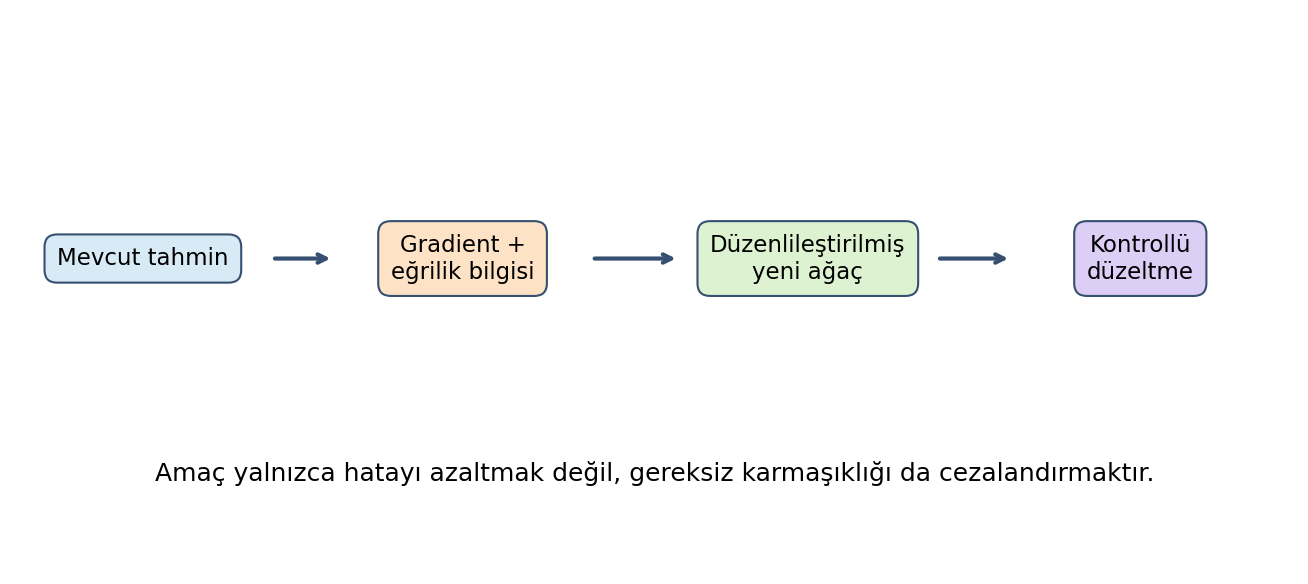

### 8.2 LightGBM'in arka planı: Büyük veride daha hızlı boosting

Klasik tree algoritmaları her feature için çok sayıda olası eşik deneyebilir. Veri büyüdükçe bu arama pahalı hale gelir. LightGBM, sürekli değerleri histogram kutularına ayırarak aday bölme sayısını azaltır.

LightGBM'in ayırt edici özelliklerinden biri ağacı **leaf-wise** büyütmesidir:

1. Mevcut ağacın bütün yapraklarını inceler.
2. Loss'u en fazla azaltacak yaprağı seçer.
3. Yalnızca o yaprağı ikiye böler.
4. Sonraki turda yeniden en yüksek kazançlı yaprağı arar.

Bu yöntem aynı ağaç sayısıyla hızlı biçimde güçlü ilişkiler öğrenebilir. Fakat bir dal diğerlerinden çok daha derinleşebildiği için küçük veri setlerinde overfitting riski oluşabilir.

#### LightGBM'i başarılı yapan faktörler

- **Histogram tabanlı bölmeler:** Hesaplama ve bellek maliyetini azaltır.
- **Leaf-wise büyüme:** En fazla iyileşme sağlayan dala öncelik verir.
- **Büyük veri ölçeği:** Çok satırlı ve çok feature'lı tabular problemlerde hızlıdır.
- **Kategorik feature desteği:** Uygun veri tipiyle bazı kategorik değişkenleri özel olarak işleyebilir.
- **Satır/feature örnekleme:** Hızı artırıp overfitting'i sınırlayabilir.
- **Paralel ve dağıtık çalışma seçenekleri:** Büyük eğitim işlerinde ölçeklenebilir.

LightGBM kullanırken `num_leaves`, `max_depth` ve `min_child_samples` ayarlarını birlikte düşünmem gerekir.

### LightGBM ağacı nasıl büyütür?

Level-wise yaklaşım aynı seviyeyi dengeli büyütürken LightGBM en fazla kazanç sağlayan yaprağa öncelik verir.

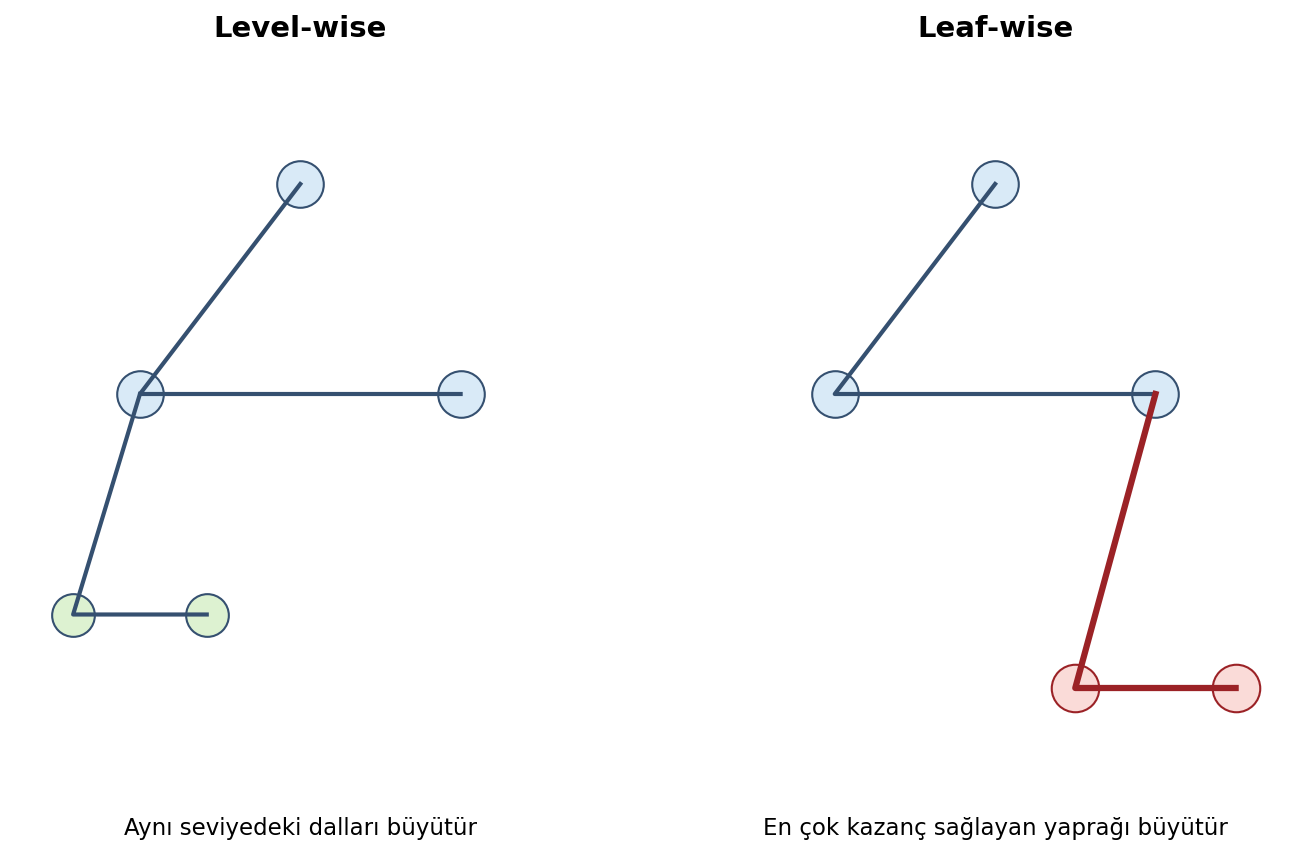

### 8.3 CatBoost'un arka planı: Kategorik değişkenleri güvenli kullanmak

Kategorik değişkenleri one-hot encoding ile açmak, kategori sayısı arttığında çok geniş veri üretir. Kategoriyi hedef ortalamasıyla dönüştürmek ise aynı satırın hedef bilgisinin kendi feature'ına karışmasına ve target leakage oluşmasına neden olabilir.

CatBoost bu problemi **ordered target statistics** yaklaşımıyla ele alır:

1. Eğitim verisi için rastgele bir sıra oluşturur.
2. Bir satırın kategorik temsilini hesaplarken yalnızca kendisinden önceki satırların hedeflerini kullanır.
3. Böylece satırın kendi hedefinin dönüşüme sızmasını azaltır.
4. Oluşturduğu güvenli kategorik temsillerle boosting ağaçlarını eğitir.

CatBoost ayrıca simetrik/oblivious tree yapıları kullanır. Aynı seviyedeki bütün düğümlerde aynı bölme koşulunun kullanılması, tahmin sürecini düzenli ve hızlı hale getirebilir.

#### CatBoost'u başarılı yapan faktörler

- **Kategorik değişkenleri doğrudan kullanabilmesi:** Büyük one-hot matrislerine olan ihtiyacı azaltır.
- **Ordered target statistics:** Target leakage ve prediction shift riskini azaltmayı amaçlar.
- **Ordered boosting:** Her gözlem için kendisinden önceki bilgiyle tahmin oluşturarak aşırı uyumu kontrol eder.
- **Simetrik ağaçlar:** Tahmin işlemini hızlı ve model yapısını daha düzenli hale getirir.
- **Güçlü varsayılan ayarlar:** Çok fazla tuning yapmadan rekabetçi sonuç verebilir.

Sigorta verisindeki bölge, araç markası ve yakıt tipi gibi kategorik feature'lar CatBoost için doğal bir kullanım alanıdır.

### CatBoost kategorik veriyi nasıl korur?

Bir gözlemin kategorik dönüşümünü hesaplarken kendi hedefini kullanmamak, modelin cevabı önceden görmesini engellemeye yardımcı olur.

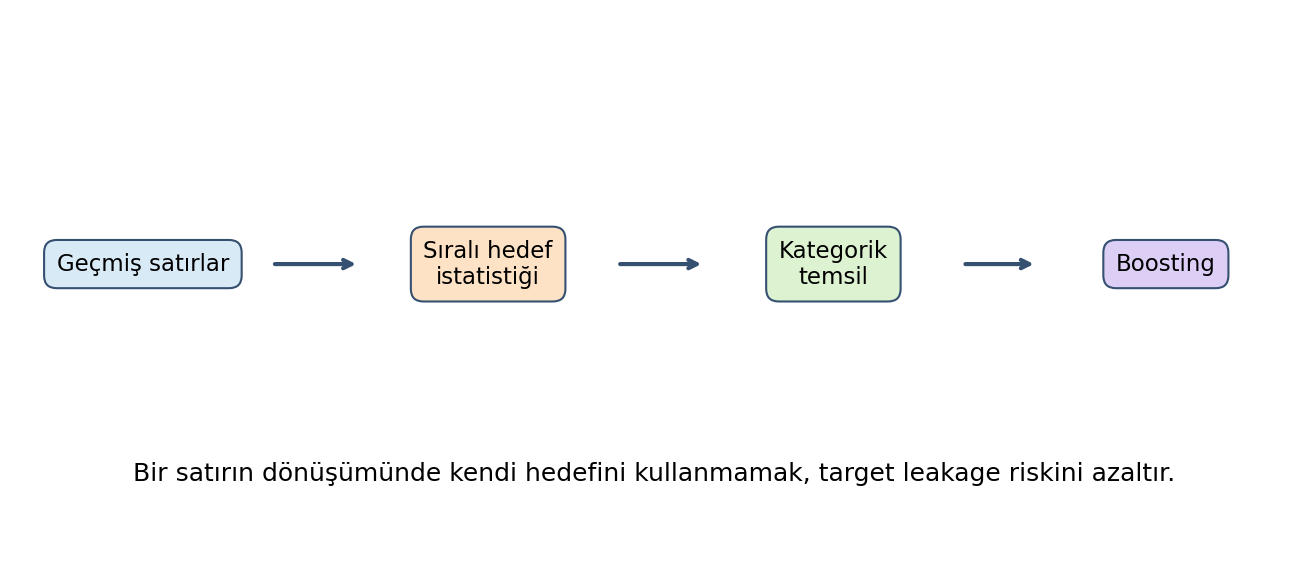

### 8.4 AdaBoost'un arka planı: Zor örneklere tekrar bakmak

AdaBoost'un çıkış noktası, tek bir basit modelin her gözlemi iyi öğrenememesidir. Model, önceki turda yanlış tahmin ettiği gözlemlere daha fazla ağırlık vererek yeni zayıf öğreniciyi zor örneklere yönlendirir.

Adım adım:

1. Bütün gözlemlere eşit ağırlık veririm.
2. Basit bir sınıflandırıcı eğitirim.
3. Yanlış sınıflanan gözlemlerin ağırlığını yükseltirim.
4. Sonraki model bu gözlemleri düzeltmeye daha fazla çalışır.
5. Başarılı zayıf modellere final oylamasında daha yüksek ağırlık veririm.

#### AdaBoost'u başarılı yapan faktörler

- **Uyarlanabilir odak:** Her turda veri setinin zor kalan bölümüne yönelir.
- **Basit modellerin birleşimi:** Tek başına yetersiz decision stump'ları güçlü bir sınıflandırıcıya dönüştürür.
- **Ağırlıklı oylama:** Daha başarılı öğrenicilere daha fazla söz hakkı verir.
- **Az sayıda temel ayar:** Mantığını anlatmak ve başlangıç deneyi yapmak kolaydır.
- **Net sınırlar:** Temiz veride karmaşık olmayan karar sınırlarını aşamalı şekilde geliştirebilir.

Ancak yanlış etiketlenmiş veya aşırı uç gözlemler sürekli yüksek ağırlık kazanabilir. Bu nedenle AdaBoost gürültüye diğer boosting modellerinden daha hassas olabilir.

### AdaBoost'ta modellerin söz hakkı

Final karar, bütün modellerin eşit oyundan değil; performanslarına göre ağırlıklandırılmış oylarından oluşur.

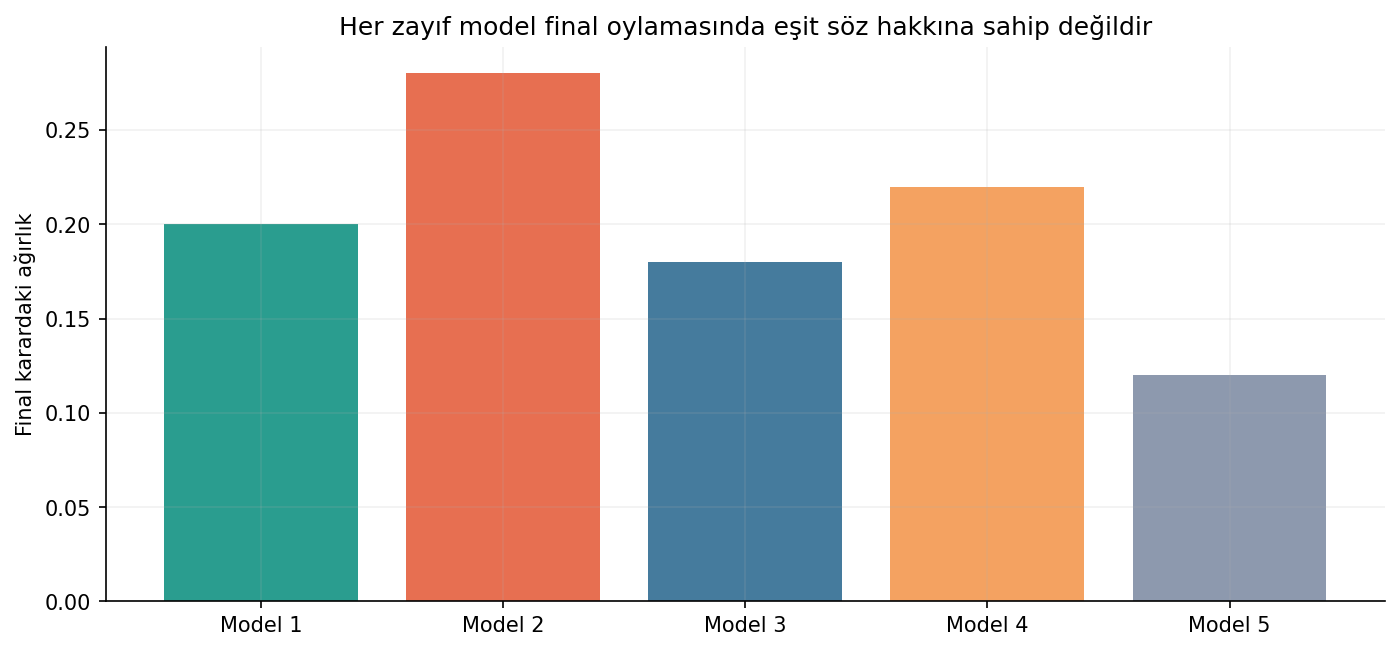

## 9. Boosting'de overfitting'i nasıl kontrol ederim?

Boosting güçlü olduğu için yanlış ayarlarla eğitim verisini fazla öğrenebilir. Kontrol edebileceğim başlıca noktalar:

- Ağaç derinliğini sınırlamak
- Öğrenme oranını düşürmek
- Ağaç sayısını validation verisiyle seçmek
- Satır ve kolon örneklemesi kullanmak
- Minimum leaf büyüklüğünü artırmak
- L1/L2 regularization kullanmak
- Early stopping uygulamak

Burada train skorunun yükselmesi tek başına başarı değildir. Asıl sorum şudur:

> Daha sonra göreceğim poliçelerde de aynı performansı koruyabilecek miyim?

## 10. Bagging ve Boosting karşılaştırması

İki yaklaşım da çok sayıda ağacı bir araya getirir; fakat çalışma biçimleri farklıdır.

### Bagging ve Boosting

Bagging bağımsız modelleri birleştirirken boosting modelleri birbirinin devamı olarak eğitir.



| Soru | Bagging | Boosting |
|---|---|---|
| Modeller nasıl eğitilir? | Birbirinden bağımsız ve paralel | Birbirini takip eden sıralı turlar |
| Her model hangi veriye bakar? | Farklı bootstrap örnekleri | Önceki hatalara göre şekillenen problem |
| Tahmin nasıl birleşir? | Ortalama veya çoğunluk oyu | Ağırlıklı katkıların toplamı |
| Temel amacı nedir? | Varyansı ve kararsızlığı azaltmak | Hataları aşamalı azaltmak |
| Gürültüye dayanıklılık | Genellikle daha dayanıklı | Gürültülü gözlemlere daha duyarlı olabilir |
| Paralel eğitim | Daha kolay | Sıralı yapı nedeniyle daha sınırlı |
| Tipik örnek | Random Forest | XGBoost, LightGBM, CatBoost |

Bagging veya boosting seçimini yalnızca leaderboard skoruna göre yapmam. Eğitim süresi, tahmin gecikmesi, açıklanabilirlik, bakım kolaylığı ve veri değişimine dayanıklılık da production kararının parçasıdır.

# Uygulama — Motor Sigortasında Hasar Gerçekleşir mi?

French Motor Third-Party Liability veri setinde her satır bir poliçeyi temsil eder. Bu hafta hedefimi şöyle tanımlıyorum:

> Poliçenin gözlem süresi içinde en az bir hasar gerçekleşir mi?

Orijinal hedef `ClaimNb` hasar sayısını içerir. Sınıflandırma problemi için `ClaimNb > 0` koşuluyla `has_claim` hedefini oluşturacağım.

### Aktüeryal problem çerçevesi

Aynı sigorta verisiyle occurrence, frequency ve severity problemleri kurulabilir. Bu hafta yalnızca hasar gerçekleşip gerçekleşmediğine odaklanıyorum.

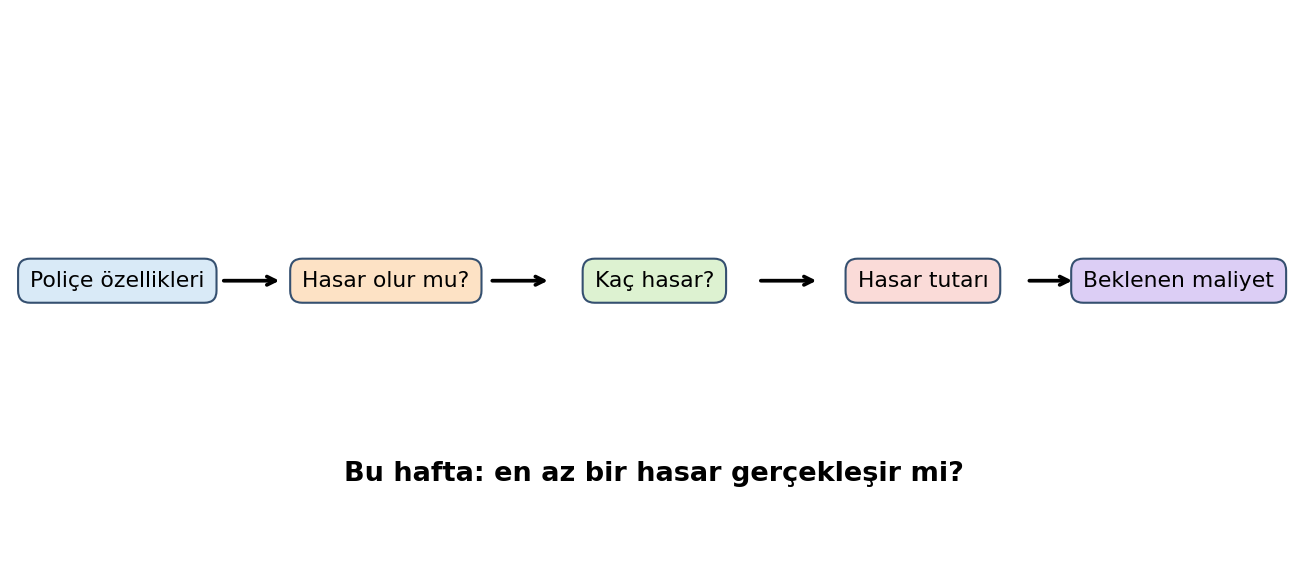

In [ ]:
# Veri setini OpenML üzerinden yüklüyorum.
# İlk çalıştırma internet bağlantısına bağlı olarak birkaç dakika sürebilir.
from sklearn.datasets import fetch_openml
import pandas as pd

insurance = fetch_openml(
    data_id=41214,
    as_frame=True,
    parser="auto"
)

df = insurance.frame.copy()
print(df.shape)
df.head()

## 11. Veriyi tanıyalım

Model kurmadan önce şu sorulara cevap ararım:

- Her satır gerçekten bir poliçe mi?
- `ClaimNb` dağılımı nasıl?
- `Exposure` neden önemli?
- Kategorik değişkenler hangileri?
- Aykırı görünen değerler veri hatası mı, gerçek bir risk grubu mu?
- `IDpol` modelde kullanılmalı mı?

Bu sorular, model seçiminden önce problem tanımını netleştirir.

In [ ]:
df.info()

In [ ]:
df.describe(include="all").T

In [ ]:
# Hasar sayısının dağılımı
df["ClaimNb"].value_counts(dropna=False).sort_index().head(10)

## 12. Eğitim amacıyla tarih değişkeni ekleyelim

Orijinal veri setinde poliçe tarihi bulunmuyor. Zaman bazlı validation ve production senaryosunu gösterebilmek için 19 Ekim 2016 ile 19 Ekim 2026 arasında tekrar üretilebilir rastgele tarihler ekliyorum.

Bu tarihlerin hasarla gerçek bir ilişkisi olmadığını açıkça not ediyorum. Tarihi modele güçlü bir feature gibi vermek için değil, doğru validation düzenini göstermek için kullanacağım.

In [ ]:
import numpy as np

rng = np.random.default_rng(seed=42)
start_date = pd.Timestamp("2016-10-19")
end_date = pd.Timestamp("2026-10-19")

random_days = rng.integers(
    low=0,
    high=(end_date - start_date).days + 1,
    size=len(df)
)

df["PolicyDate"] = start_date + pd.to_timedelta(random_days, unit="D")
df["has_claim"] = (df["ClaimNb"].astype(float) > 0).astype(int)

df[["PolicyDate", "ClaimNb", "has_claim"]].head()

In [ ]:
# Sınıf dağılımını inceleyelim.
target_distribution = (
    df["has_claim"]
    .value_counts(normalize=True)
    .rename("oran")
    .to_frame()
)

target_distribution

### Buradaki ilk kritik sonuç

Hasar gerçekleşmeyen poliçeler çoğunluktadır. Bu nedenle yalnızca accuracy kullanırsam modelin iş açısından faydalı olup olmadığını anlayamayabilirim.

Örneğin model bütün poliçeler için “hasar olmayacak” derse yüksek accuracy elde edebilir; fakat riskli poliçeleri hiç bulamaz. Bu nedenle recall, precision, F1, ROC-AUC ve özellikle PR-AUC değerlerini birlikte okuyacağım.

## 13. Zaman bazlı train, validation ve test ayrımı

Boosting modellerinde validation seti yalnızca skor ölçmek için değil, kaç tur öğrenmem gerektiğini belirlemek için de kullanılır.

- Train: modeli eğitirim.
- Validation: model ve threshold kararlarını veririm.
- Test: tüm kararlar bittikten sonra yalnızca bir kez final performansı ölçerim.

In [ ]:
df = df.sort_values("PolicyDate").reset_index(drop=True)

train_df = df[df["PolicyDate"] < "2023-01-01"].copy()
valid_df = df[
    (df["PolicyDate"] >= "2023-01-01")
    & (df["PolicyDate"] < "2025-01-01")
].copy()
test_df = df[df["PolicyDate"] >= "2025-01-01"].copy()

pd.DataFrame({
    "veri": ["train", "validation", "test"],
    "satir": [len(train_df), len(valid_df), len(test_df)],
    "hasar_orani": [
        train_df["has_claim"].mean(),
        valid_df["has_claim"].mean(),
        test_df["has_claim"].mean()
    ]
})

## 14. Feature ve preprocessing kararları

`IDpol` yalnızca kimlik bilgisidir; modele vermem. `ClaimNb` hedefi oluşturmak için kullanıldığı için feature olarak kalırsa doğrudan target leakage oluşur. `PolicyDate` ise yalnızca veri ayırmak için eklediğim yapay tarihtir.

Bu üç kolonu model girdisinden çıkaracağım.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

TARGET = "has_claim"
DROP_COLUMNS = ["IDpol", "ClaimNb", "PolicyDate", TARGET]

feature_columns = [c for c in df.columns if c not in DROP_COLUMNS]

X_train = train_df[feature_columns]
y_train = train_df[TARGET]
X_valid = valid_df[feature_columns]
y_valid = valid_df[TARGET]
X_test = test_df[feature_columns]
y_test = test_df[TARGET]

categorical_columns = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_columns = X_train.select_dtypes(exclude=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
    ]
)

print("Sayısal:", numeric_columns)
print("Kategorik:", categorical_columns)

## 15. Bagging ve boosting modellerini aynı koşullarda karşılaştıralım

Önce Logistic Regression ile doğrusal bir baseline, ardından Random Forest ile bagging ve HistGradientBoosting ile boosting yaklaşımını karşılaştıracağım.

Veri büyük olduğu için ders süresini korumak amacıyla train setinden tekrar üretilebilir bir örneklem alabilirim. Validation ve test setlerine dokunmam.

In [ ]:
# Ders bilgisayarlarında süreyi kontrol etmek için isteğe bağlı örneklem.
MAX_TRAIN_ROWS = 80_000

if len(X_train) > MAX_TRAIN_ROWS:
    sampled_index = X_train.sample(MAX_TRAIN_ROWS, random_state=42).index
    X_train_model = X_train.loc[sampled_index]
    y_train_model = y_train.loc[sampled_index]
else:
    X_train_model = X_train
    y_train_model = y_train

print(X_train_model.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest — Bagging": RandomForestClassifier(
        n_estimators=150,
        max_depth=10,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    ),
    "HistGradientBoosting — Boosting": HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=42,
    ),
}

def evaluate(y_true, probability, threshold=0.50):
    prediction = (probability >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
    }

In [ ]:
results = []
fitted_models = {}

for model_name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model),
    ])

    pipeline.fit(X_train_model, y_train_model)
    valid_probability = pipeline.predict_proba(X_valid)[:, 1]

    results.append({
        "model": model_name,
        **evaluate(y_valid, valid_probability)
    })
    fitted_models[model_name] = pipeline

validation_results = (
    pd.DataFrame(results)
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
)

validation_results

### Sonucu nasıl okuyacağım?

- `accuracy`: Bütün kararların ne kadarı doğru?
- `precision`: Riskli dediğim poliçelerin ne kadarı gerçekten hasarlı?
- `recall`: Gerçekten hasarlı poliçelerin ne kadarını yakaladım?
- `ROC-AUC`: Pozitifleri negatiflerden genel olarak ne kadar iyi sıralıyorum?
- `PR-AUC`: Pozitif sınıf az olduğunda riskli poliçeleri bulma kalitem nasıl?

Aktüeryal açıdan modelin olasılıklarının kalibrasyonu da önemlidir. İyi sıralama yapan bir model, verdiği `%20` olasılığın gerçekten yaklaşık `%20` hasar oranına karşılık geldiğini garanti etmez.

## 16. Threshold teknik değil, iş kararıdır

Model olasılık üretir; `0.50` eşiği doğanın verdiği zorunlu bir sınır değildir. İnceleme kapasitesi, risk iştahı ve hataların maliyeti threshold kararını belirler.

- Threshold düşerse daha fazla riskli poliçe yakalayabilirim; yanlış alarm artabilir.
- Threshold yükselirse daha seçici olurum; gerçek riskli poliçeleri kaçırabilirim.

In [ ]:
best_model_name = validation_results.iloc[0]["model"]
best_pipeline = fitted_models[best_model_name]
valid_probability = best_pipeline.predict_proba(X_valid)[:, 1]

threshold_results = []
for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    threshold_results.append({
        "threshold": threshold,
        **evaluate(y_valid, valid_probability, threshold=threshold)
    })

pd.DataFrame(threshold_results)

## 17. Final test: kararlar bittikten sonra

Modeli ve threshold'u validation setiyle seçtikten sonra test setini yalnızca final ölçüm için kullanırım. Test sonucuna bakıp tekrar tekrar ayar yaparsam test verisini de eğitim sürecine dahil etmiş olurum.

In [ ]:
# Örnek olarak validation sonucunda seçtiğim threshold'u buraya yazacağım.
SELECTED_THRESHOLD = 0.10

test_probability = best_pipeline.predict_proba(X_test)[:, 1]
test_result = evaluate(
    y_test,
    test_probability,
    threshold=SELECTED_THRESHOLD
)

pd.Series(test_result, name=best_model_name)

## 18. XGBoost, LightGBM ve CatBoost için isteğe bağlı deney alanı

Bu kütüphaneler ortamda kurulu olmayabilir. Dersin ana akışını kurulum problemine bağlamamak için temel uygulamayı scikit-learn ile tamamladım. Aşağıdaki hücreleri karşılaştırma veya ödev amacıyla kullanabilirim.

In [ ]:
# Gerektiğinde kurulabilir:
# %pip install -q xgboost lightgbm catboost

# AdaBoost örneği — scikit-learn ile birlikte gelir.
# from sklearn.ensemble import AdaBoostClassifier
# from sklearn.tree import DecisionTreeClassifier
# ada_model = AdaBoostClassifier(
#     estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
#     n_estimators=200,
#     learning_rate=0.05,
#     random_state=42,
# )

# XGBoost örneği
# from xgboost import XGBClassifier
# xgb_model = XGBClassifier(
#     n_estimators=300,
#     learning_rate=0.05,
#     max_depth=4,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     eval_metric="logloss",
#     random_state=42,
# )

In [ ]:
# LightGBM örneği
# from lightgbm import LGBMClassifier
# lgbm_model = LGBMClassifier(
#     n_estimators=300,
#     learning_rate=0.05,
#     num_leaves=31,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     random_state=42,
# )

# CatBoost örneği — kategorik feature'ları doğrudan kullanabilir.
# from catboost import CatBoostClassifier
# cat_model = CatBoostClassifier(
#     iterations=300,
#     learning_rate=0.05,
#     depth=6,
#     loss_function="Logloss",
#     verbose=False,
#     random_seed=42,
# )

# LAB — 60 dakikalık uygulama

## Bölüm A — Veri keşfi

1. Her kolonun iş anlamını açıklayın.
2. `ClaimNb`, `Exposure`, `DrivAge` ve `BonusMalus` dağılımlarını inceleyin.
3. En az bir hasarı olan poliçelerin oranını hesaplayın.
4. `Exposure` kısa olan poliçelerle uzun olanları karşılaştırın.

## Bölüm B — Modelleme

1. Logistic Regression baseline kurun.
2. Random Forest ve bir boosting modeli eğitin.
3. Modelleri accuracy, recall, ROC-AUC ve PR-AUC ile karşılaştırın.
4. En iyi model için farklı threshold değerlerini deneyin.

## Bölüm C — Aktüeryal tartışma

1. Yanlış negatif ve yanlış pozitif kararların iş maliyetini tanımlayın.
2. Tarih kolonunun yapay olmasının sonuçlarını tartışın.
3. Modelin olasılık kalibrasyonunu neden kontrol etmemiz gerektiğini açıklayın.
4. Bu modeli prim fiyatlamasında doğrudan kullanmanın hangi riskleri taşıdığını tartışın.

## 19. Bu haftadan çıkardığım sonuçlar

- Boosting modelleri sıralı çalışır ve her yeni model önceki topluluğun hatasına odaklanır.
- Gradient Boosting küçük düzeltmeleri mevcut tahmine ekleyerek ilerler.
- AdaBoost yanlış sınıflanan gözlemlerin ağırlığını artırır.
- Öğrenme oranı ve ağaç sayısı birlikte değerlendirilmelidir.
- Bagging daha çok kararsızlığı azaltırken boosting hataları aşamalı düzeltmeye çalışır.
- Güçlü model, doğru validation tasarımının yerine geçmez.
- Dengesiz sigorta probleminde accuracy tek başına yeterli değildir.
- Model olasılığı ile iş kararı arasına threshold ve maliyet değerlendirmesi girer.

Bir sonraki aşamada modelin yalnızca skoruna değil; **kalibrasyonuna, açıklanabilirliğine, deney takibine ve production ortamında izlenmesine** odaklanacağım.